<a href="https://colab.research.google.com/github/yihan4326/MSSP607/blob/main/Assignments/assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# insert and read data
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

project_root = Path('/content/drive/MyDrive/using-pandas-dataframe')
data_path = project_root / 'data' / 'data_academic_performance.csv'

df = pd.read_csv(data_path)
print('Data shape:', df.shape)
df.head()


Mounted at /content/drive
Data shape: (12411, 45)


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


In [3]:
# clean data
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove the empty unnamed column
df = df.drop(
    columns=df.columns[df.columns.str.contains("Unnamed")],
    errors="ignore")

# Remove extra spaces from text values
text_columns = df.select_dtypes(include="object").columns
for column in text_columns:
    df[column] = df[column].str.strip()

# Replace invalid values in parental education with missing values
df["EDU_FATHER"] = df["EDU_FATHER"].replace(
    ["0", "Not sure"],
    pd.NA)

df["EDU_MOTHER"] = df["EDU_MOTHER"].replace(
    ["0", "Not sure"],
    pd.NA)

# Replace the invalid stratum value with a missing value
df["STRATUM"] = df["STRATUM"].replace("0", pd.NA)

# Make sure the global assessment score is numeric
df["G_SC"] = pd.to_numeric(df["G_SC"],
    errors="coerce")

# Check the cleaned data
print("Cleaned data shape:", df.shape)
print("Missing values in important columns:")
print(df[["GENDER",
    "EDU_FATHER",
    "EDU_MOTHER",
    "STRATUM",
    "G_SC"]].isna().sum())
df.head()

Cleaned data shape: (12411, 44)
Missing values in important columns:
GENDER          0
EDU_FATHER    798
EDU_MOTHER    567
STRATUM        14
G_SC            0
dtype: int64


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,INTERNET,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,Yes,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,Yes,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,<NA>,<NA>,Independent,Home,Stratum 2,Level 2,Five,No,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,<NA>,<NA>,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,Yes,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,Yes,...,98,100,71,189,198,98,5,4,4,2


In [4]:
# overall performance
df["G_SC"].describe()

,G_SC
count,12411.000000
mean,162.710499
std,23.112479
min,37.000000
25%,147.000000
50%,163.000000
75%,179.000000
max,247.000000


In [5]:
#parental education findings
# Keep rows with valid father education and global scores
father_data = df.dropna(
    subset=["EDU_FATHER", "G_SC"])

# Summarize global scores for all father education groups
father_all_summary = (
    father_data
    .groupby("EDU_FATHER")["G_SC"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean"))

father_all_summary


,count,mean,median,std
EDU_FATHER,,,,
Complete primary,824,155.20,155.0,22.41
Incomplete primary,735,155.73,156.0,20.94
Incomplete Secundary,1091,156.54,157.0,21.74
Ninguno,123,156.63,159.0,23.19
Complete Secundary,2843,158.79,159.0,22.11
Incomplete technical or technological,277,162.10,162.0,21.88
Complete technique or technology,1194,164.03,164.0,22.17
Incomplete Professional Education,425,166.92,168.0,22.69
Complete professional education,3016,167.77,169.0,23.03


In [6]:
# Select the two father education groups
parent_groups = [
    "Ninguno",
    "Postgraduate education"
]

father_comparison_data = father_data[
    father_data["EDU_FATHER"].isin(parent_groups)
]

# Calculate descriptive statistics
father_comparison = (
    father_comparison_data
    .groupby("EDU_FATHER")["G_SC"]
    .agg(["count", "mean", "median", "std"])
    .reindex(parent_groups))
father_comparison


,count,mean,median,std
EDU_FATHER,,,,
Ninguno,123,156.634146,159.0,23.188560
Postgraduate education,1085,176.985253,179.0,21.734132


In [7]:
# Keep rows with valid mother education and global scores
mother_data = df.dropna(
    subset=["EDU_MOTHER", "G_SC"])

# Summarize all mother education groups
mother_all_summary = (
    mother_data
    .groupby("EDU_MOTHER")["G_SC"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean"))

mother_all_summary

,count,mean,median,std
EDU_MOTHER,,,,
Ninguno,34,149.705882,152.5,27.930139
Incomplete primary,541,154.853974,155.0,21.636024
Complete primary,713,155.336606,155.0,22.012293
Incomplete Secundary,1056,155.672348,156.0,21.928635
Complete Secundary,3106,158.470702,159.0,21.949597
Incomplete technical or technological,341,161.879765,164.0,20.744388
Complete technique or technology,1495,163.242140,163.0,21.943495
Incomplete Professional Education,502,166.685259,168.0,22.931830
Complete professional education,3059,168.845374,170.0,22.978321


In [8]:
# Select the two mother education groups
mother_comparison_data = mother_data[
    mother_data["EDU_MOTHER"].isin(parent_groups)
]

# Calculate descriptive statistics
mother_comparison = (
    mother_comparison_data
    .groupby("EDU_MOTHER")["G_SC"]
    .agg(["count", "mean", "median", "std"])
    .reindex(parent_groups)
)

mother_comparison

,count,mean,median,std
EDU_MOTHER,,,,
Ninguno,34,149.705882,152.5,27.930139
Postgraduate education,997,175.636911,178.0,22.119758


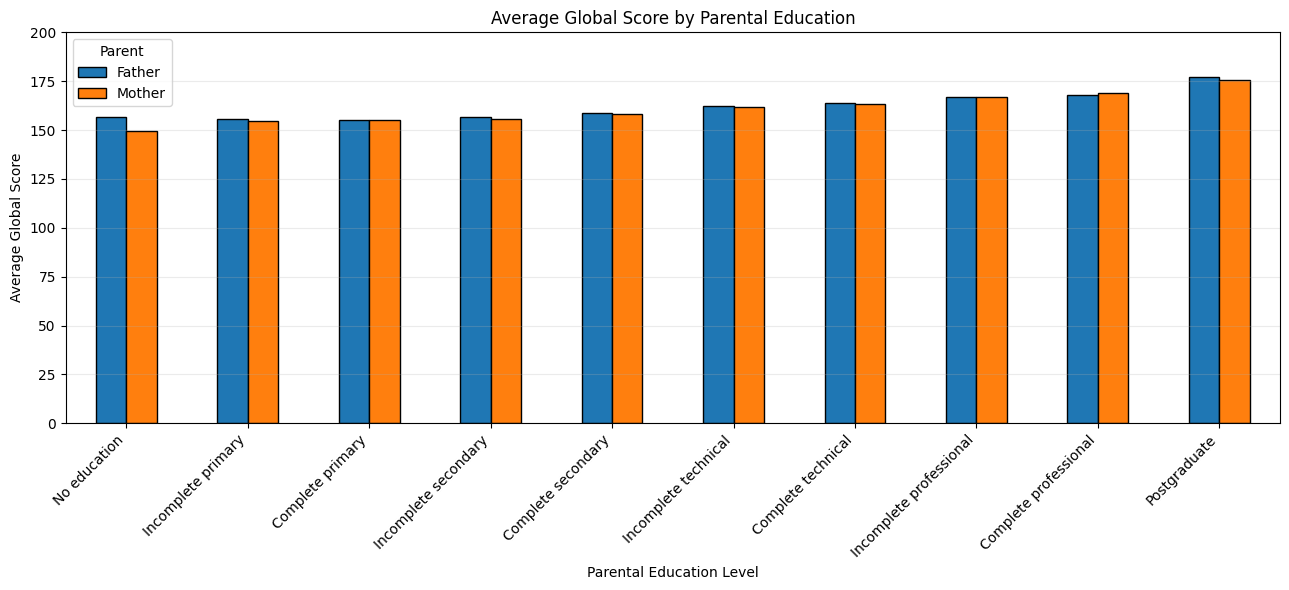

In [9]:
# Parental education visualization

# Set the correct order of parental education
education_order = [
    "Ninguno",
    "Incomplete primary",
    "Complete primary",
    "Incomplete Secundary",
    "Complete Secundary",
    "Incomplete technical or technological",
    "Complete technique or technology",
    "Incomplete Professional Education",
    "Complete professional education",
    "Postgraduate education"
]

# Create shorter labels for the chart
education_labels = [
    "No education",
    "Incomplete primary",
    "Complete primary",
    "Incomplete secondary",
    "Complete secondary",
    "Incomplete technical",
    "Complete technical",
    "Incomplete professional",
    "Complete professional",
    "Postgraduate"
]

# Calculate mean scores by father's education
father_means = (
    father_data
    .groupby("EDU_FATHER")["G_SC"]
    .mean()
    .reindex(education_order)
)

# Calculate mean scores by mother's education
mother_means = (
    mother_data
    .groupby("EDU_MOTHER")["G_SC"]
    .mean()
    .reindex(education_order)
)

# Combine father and mother results
parent_education_means = pd.DataFrame({
    "Father": father_means.values,
    "Mother": mother_means.values
}, index=education_labels)

# Create the grouped bar chart
parent_education_means.plot(
    kind="bar",
    figsize=(13, 6),
    edgecolor="black"
)

plt.title(
    "Average Global Score by Parental Education"
)
plt.xlabel("Parental Education Level")
plt.ylabel("Average Global Score")
plt.xticks(
    rotation=45,
    ha="right"
)
plt.legend(
    title="Parent"
)
plt.ylim(0, 200)
plt.grid(
    axis="y",
    alpha=0.25
)
plt.tight_layout()

# Save the figure
plt.savefig(
    project_root / "parental_education_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Stratum findings

# Keep rows with valid stratum and global scores
stratum_data = df.dropna(
    subset=["STRATUM", "G_SC"])

# Set the correct order of the strata
stratum_order = [
    "Stratum 1",
    "Stratum 2",
    "Stratum 3",
    "Stratum 4",
    "Stratum 5",
    "Stratum 6"]

# Calculate descriptive statistics for each stratum
stratum_summary = (
    stratum_data
    .groupby("STRATUM")["G_SC"]
    .agg(["count", "mean", "median", "std"])
    .reindex(stratum_order))

# Display the results
stratum_summary

,count,mean,median,std
STRATUM,,,,
Stratum 1,1709,152.352838,152.0,21.937401
Stratum 2,4029,158.199305,158.0,22.278029
Stratum 3,4045,163.815328,164.0,21.693970
Stratum 4,1578,172.002535,174.0,21.469094
Stratum 5,633,177.387046,179.0,21.543236
Stratum 6,403,181.511166,184.0,21.879401


In [11]:
# Compare the lowest and highest strata
stratum_comparison = stratum_summary.loc[
    ["Stratum 1", "Stratum 6"]]

stratum_comparison

,count,mean,median,std
STRATUM,,,,
Stratum 1,1709,152.352838,152.0,21.937401
Stratum 6,403,181.511166,184.0,21.879401


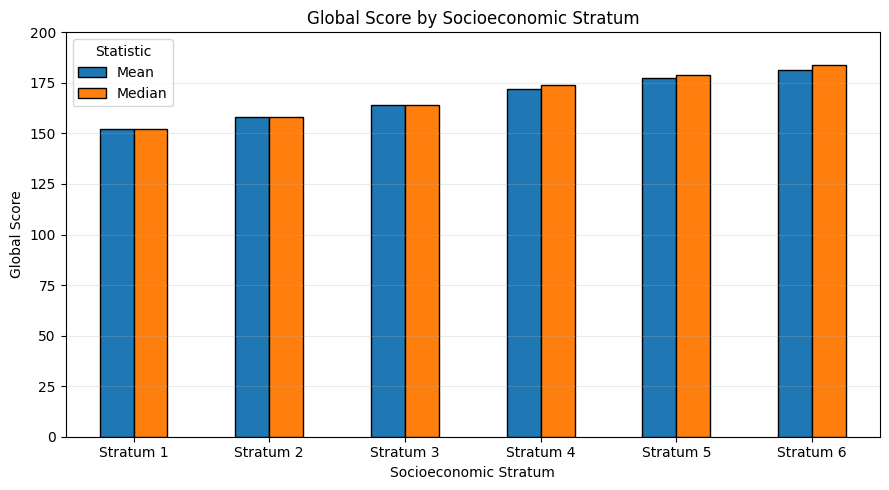

In [13]:
# Socioeconomic stratum visualization

# Select the mean and median from the stratum summary
stratum_plot_data = stratum_summary[
    ["mean", "median"]
]

# Rename the columns for the chart legend
stratum_plot_data = stratum_plot_data.rename(
    columns={
        "mean": "Mean",
        "median": "Median"
    }
)

# Create the grouped bar chart
stratum_plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title(
    "Global Score by Socioeconomic Stratum"
)
plt.xlabel("Socioeconomic Stratum")
plt.ylabel("Global Score")
plt.xticks(
    rotation=0
)
plt.legend(
    title="Statistic"
)
plt.ylim(0, 200)
plt.grid(
    axis="y",
    alpha=0.25
)
plt.tight_layout()

# Save the figure
plt.savefig(
    project_root / "stratum_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Gender findings

# Keep rows with valid gender and global scores
gender_data = df.dropna(
    subset=["GENDER", "G_SC"]
)

# Set the order of gender groups
gender_order = ["F", "M"]

# Calculate descriptive statistics for each gender
gender_summary = (
    gender_data
    .groupby("GENDER")["G_SC"]
    .agg(["count", "mean", "median", "std"])
    .reindex(gender_order)
)

# Display the results
gender_summary

,count,mean,median,std
GENDER,,,,
F,5043,161.278207,162.0,22.332939
M,7368,163.690825,164.0,23.582616


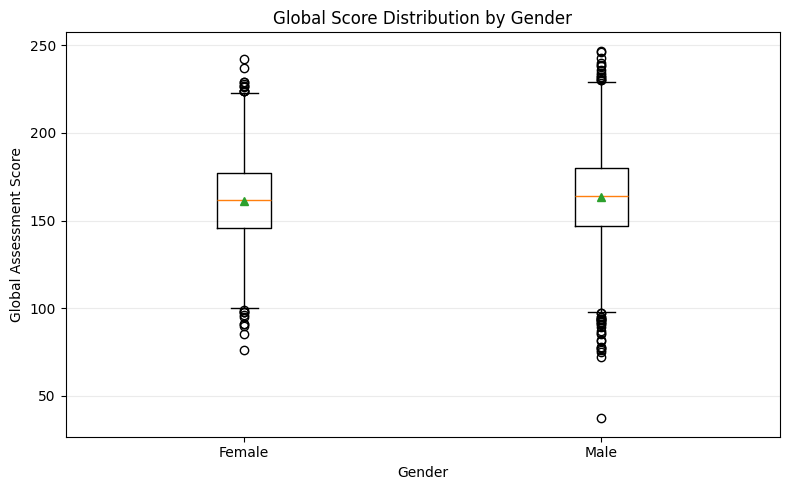

In [14]:
# Gender visualization

# Select female global scores
female_scores = gender_data.loc[
    gender_data["GENDER"] == "F",
    "G_SC"
]

# Select male global scores
male_scores = gender_data.loc[
    gender_data["GENDER"] == "M",
    "G_SC"
]

# Create the boxplot
plt.figure(
    figsize=(8, 5)
)

plt.boxplot(
    [
        female_scores,
        male_scores
    ],
    tick_labels=[
        "Female",
        "Male"
    ],
    showmeans=True
)

plt.title(
    "Global Score Distribution by Gender"
)
plt.xlabel("Gender")
plt.ylabel("Global Assessment Score")
plt.grid(
    axis="y",
    alpha=0.25
)
plt.tight_layout()

# Save the figure
plt.savefig(
    project_root / "gender_score_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()